In [ ]:
import pandas as pd
import numpy as np
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

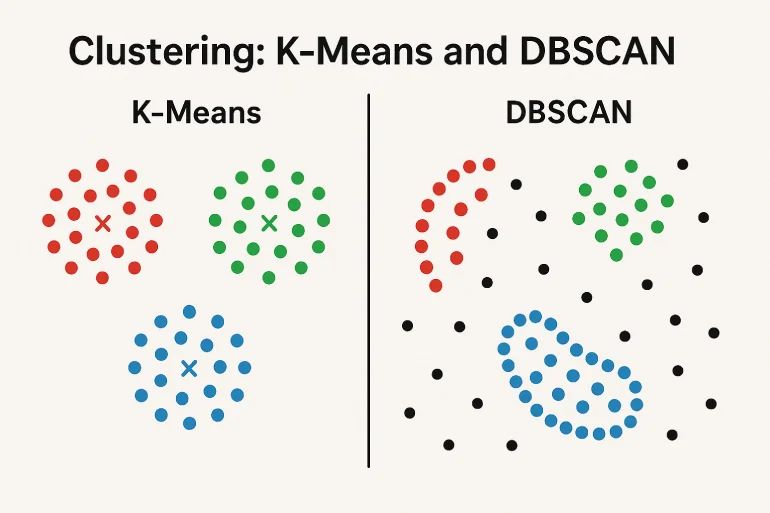

# DBSCAN CLUSTERING

## 1. Introduction

DBSCAN stands for **Density-Based Spatial Clustering of Applications with Noise**.

DBSCAN is an unsupervised machine learning algorithm used to group similar data points based on their density.

It identifies clusters by finding areas where many data points are located close to each other.

The main idea is:
- Data points located closely together are grouped into clusters.
- Data points located far away from other points are treated as noise or outliers.

**Example:**

Imagine a shopping mall has customers visiting different areas.

- Customers who frequently visit the same area can form a group.
- Customers who are located far away from these groups may be considered outliers.

This is the basic idea behind DBSCAN.

## 2. Important Parameters in DBSCAN

DBSCAN mainly uses two important parameters.

### 2.1 Epsilon (Eps)

**Definition:** Epsilon is the maximum distance between two data points to consider them neighbours.

In simple words, Epsilon defines how close two points should be to become neighbours.

**Example:**

If Epsilon = 3, DBSCAN considers points within a distance of 3 units as neighbours.

### 2.2 MinPts (Minimum Points)

**Definition:** MinPts is the minimum number of data points required within the Epsilon radius to form a dense region.

**Example:**

If MinPts = 4, at least 4 points must be present within the Epsilon neighbourhood for a point to be considered a core point.

## 3. Types of Points in DBSCAN

DBSCAN classifies data points into three main types.

### 3.1 Core Point

A Core Point is a data point that has at least the minimum number of points (MinPts) within its Epsilon neighbourhood, including itself.

**Example:**

If MinPts = 4 and a point has 5 points within its Epsilon neighbourhood, it is a Core Point.

### 3.2 Border Point

A Border Point has fewer than MinPts points within its own Epsilon neighbourhood but lies within the neighbourhood of a Core Point.

**Example:**

A point has only 2 points in its neighbourhood, but it is close to a Core Point. Therefore, it is considered a Border Point.

### 3.3 Noise Point (Outlier)

A Noise Point is a data point that does not belong to any cluster.

It is neither a Core Point nor a Border Point.

**Example:**

A data point located far away from other groups is considered a Noise Point.

## 4. How Does DBSCAN Work?

Let's understand the working process step by step.

1. Start with Data: Collect the dataset that needs to be grouped.
2. Select Parameters: Choose Epsilon (Eps) and MinPts values.
3. Find Neighbours: Identify the neighbouring points within the Epsilon radius.
4. Identify Core Points: Check whether each point has at least MinPts neighbours.
5. Form Clusters: Connect nearby Core Points and group their density-connected points.
6. Identify Border Points: Include points that are close to a Core Point but do not have enough neighbours to become Core Points themselves.
7. Identify Noise Points: Mark points that do not belong to any cluster as noise or outliers.

## 5. DBSCAN Visualization

DBSCAN identifies clusters based on the density of data points.

- Dense regions represent clusters.
- Points close to Core Points can become Border Points.
- Isolated points are considered Noise Points.

**Example:**

Imagine a dataset containing 100 data points.

- 40 points form Cluster 1.
- 35 points form Cluster 2.
- 15 points form Cluster 3.
- 10 points are identified as noise.

DBSCAN can identify these groups without specifying the number of clusters in advance.

## 6. Advantages of DBSCAN

1. No need to specify the number of clusters in advance.
2. Can identify clusters with different shapes.
3. Automatically identifies noise and outliers.
4. Works well with datasets containing irregularly shaped clusters.
5. Does not depend on calculating cluster centroids.

## 7. Disadvantages of DBSCAN

1. Choosing the correct Epsilon and MinPts values can be difficult.
2. Does not perform well when clusters have very different densities.
3. Performance can be affected by high-dimensional datasets.
4. Results may change depending on the selected parameters.

## 8. Real-Time Applications

- Customer Segmentation: Groups customers based on their location or purchasing patterns.
- Fraud Detection: Identifies unusual transactions as potential outliers.
- Geographical Data Analysis: Groups locations based on their density.
- Traffic Analysis: Identifies areas with high vehicle concentration.
- Anomaly Detection: Finds unusual data points in a dataset.
- Image Processing: Groups nearby pixels based on their characteristics.

## 9. Difference Between K-Means and DBSCAN

| K-Means | DBSCAN |
|---|---|
| Requires the number of clusters (K) in advance. | Does not require the number of clusters in advance. |
| Uses centroids to form clusters. | Uses density to form clusters. |
| Works well with spherical-shaped clusters. | Can identify irregularly shaped clusters. |
| Sensitive to outliers. | Can identify noise and outliers. |
| Every data point is assigned to a cluster. | Some data points can be marked as noise. |
| Uses the K value as an important parameter. | Uses Epsilon and MinPts as important parameters. |

## 10. Conclusion

DBSCAN is an unsupervised machine learning algorithm used to group data points based on their density. It uses two important parameters called Epsilon and MinPts. It identifies three types of points: Core Points, Border Points, and Noise Points.

DBSCAN is especially useful for identifying irregularly shaped clusters and detecting outliers in datasets.

**Important Points for Students:**

- Epsilon (Eps) = Maximum neighbourhood distance.
- MinPts = Minimum number of points required for a Core Point.
- Core Point = Point with sufficient neighbours.
- Border Point = Point connected to a Core Point but with insufficient neighbours of its own.
- Noise Point = Point that does not belong to any cluster.

In [ ]:
df = pd.read_csv('/content/Salary Data.csv')
df.head()

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
0,32.0,Male,Bachelor's,Software Engineer,5.0,90000.0
1,28.0,Female,Master's,Data Analyst,3.0,65000.0
2,45.0,Male,PhD,Senior Manager,15.0,150000.0
3,36.0,Female,Bachelor's,Sales Associate,7.0,60000.0
4,52.0,Male,Master's,Director,20.0,200000.0


In [ ]:
import pandas as pd
df = pd.read_csv('/content/diabetes.csv')
print("DataFrame Info:")
df.info()
print("\nFirst 5 rows of the DataFrame:")
display(df.head())

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

First 5 rows of the DataFrame:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [ ]:
X = df[['Glucose', 'BMI', 'Age']]

In [ ]:
X = X.dropna()

In [ ]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [ ]:
from sklearn.neighbors import NearestNeighbors

# min_samples = 2 * features = 2 * 3 = 6
min_samples = 6

In [ ]:
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors_fit = neighbors.fit(X_scaled)
distances, _ = neighbors_fit.kneighbors(X_scaled)

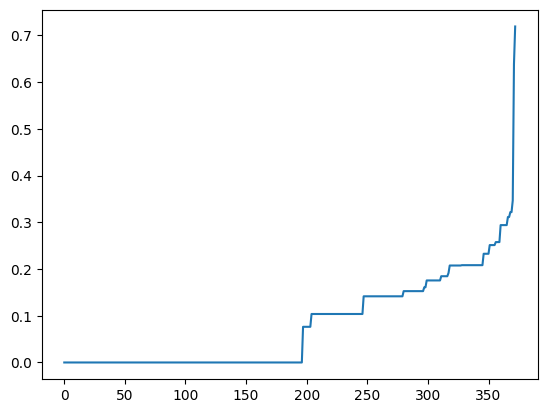

In [ ]:
distances = np.sort(distances, axis=0)
distances = distances[:, 1]
plt.plot(distances)

In [ ]:
db = DBSCAN(eps=0.15, min_samples=min_samples)
labels = db.fit_predict(X_scaled)

In [ ]:
# Easiest way - colorbar shows mapping
plt.figure(figsize=(7, 6))
scatter = plt.scatter(X_scaled[:, 0], X_scaled[:, 1],
                     c=labels, cmap='viridis', alpha=0.6)

# Colorbar explains colors
cbar = plt.colorbar(scatter)
cbar.set_label('Cluster Number')

plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.title('DBSCAN Results with eps=0.15')
plt.show()

NameError: name 'X_scaled' is not defined

<Figure size 700x600 with 0 Axes>

In [ ]:
import pandas as pd
import numpy as np

# Create data
data = {
    'Original (x)': [25, 30, 35, 40, 45, 50, 55],
    'x - μ': [-15, -10, -5, 0, 5, 10, 15],
    'Divide by σ': ['-15/10', '-10/10', '-5/10', '0/10', '5/10', '10/10', '15/10'],
    'Scaled (z)': [-1.5, -1.0, -0.5, 0, 0.5, 1.0, 1.5]
}

# Create DataFrame
df = pd.DataFrame(data)

# Display table
print(df)

   Original (x)  x - μ Divide by σ  Scaled (z)
0            25    -15      -15/10        -1.5
1            30    -10      -10/10        -1.0
2            35     -5       -5/10        -0.5
3            40      0        0/10         0.0
4            45      5        5/10         0.5
5            50     10       10/10         1.0
6            55     15       15/10         1.5


Colors:
🟣 Purple = Cluster 0 (Young customers)
🟢 Green = Cluster 1 (Senior citizens)  
🟡 Yellow = Cluster 2 (Middle age)
⚫ Black = Noise (Outliers)

Legend shows:
- Cluster 0 (👨‍👩‍👧 Young Medium-Income)
- Cluster 1 (👴 Senior High-Income)
- Cluster 2 (🧑 Middle Low-Income)
- Noise/Outliers (❌)

## Saving and Loading the DBSCAN Model

In [ ]:
import pickle

# Save the DBSCAN model
filename = 'dbscan_model.pkl'
pickle.dump(db, open(filename, 'wb'))

print(f"DBSCAN model saved to {filename}")

DBSCAN model saved to dbscan_model.pkl


### DBSCAN on Diamonds Dataset
Loading and inspecting the Excel file.

In [ ]:
import pandas as pd
# Loading Excel file
df_diamonds = pd.read_excel('/content/diamonds.xlsx')
print("Diamonds Dataset Info:")
df_diamonds.info()
display(df_diamonds.head())

Diamonds Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  object 
 3   color       53940 non-null  object 
 4   clarity     53940 non-null  object 
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), object(3)
memory usage: 4.5+ MB


,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


Selecting numerical features for clustering (Carat, Depth, Table, Price) and scaling them.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# Selecting numerical columns for clustering
features = ['carat', 'depth', 'table', 'price']
X_diamonds = df_diamonds[features].dropna()

scaler = StandardScaler()
X_diamonds_scaled = scaler.fit_transform(X_diamonds)

# Applying DBSCAN
db_diamonds = DBSCAN(eps=1.5, min_samples=8)
labels_diamonds = db_diamonds.fit_predict(X_diamonds_scaled)

df_diamonds['Cluster'] = labels_diamonds
print(f"Clusters found: {set(labels_diamonds)}")
display(df_diamonds.head())

Clusters found: {np.int64(0), np.int64(-1)}


,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z,Cluster
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,0
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31,0
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31,0
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63,0
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75,0


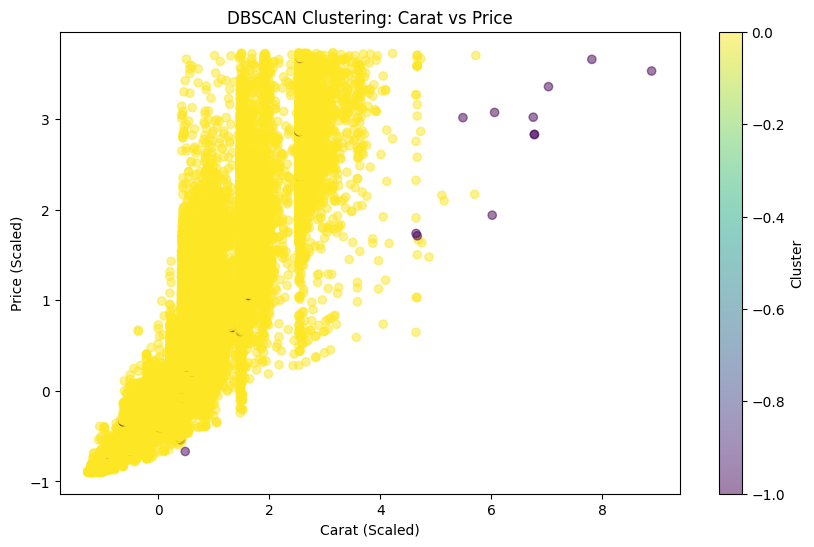

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.scatter(X_diamonds_scaled[:, 0], X_diamonds_scaled[:, 3], c=labels_diamonds, cmap='viridis', alpha=0.5)
plt.xlabel('Carat (Scaled)')
plt.ylabel('Price (Scaled)')
plt.title('DBSCAN Clustering: Carat vs Price')
plt.colorbar(label='Cluster')
plt.show()

### Predicting Clusters for New Diamond Data
We will create a small set of new data points and use our previously fitted `scaler` and `db_diamonds` model to see which clusters they fall into.

In [ ]:
import pickle
import pandas as pd

# 1. Save the diamond model specifically
diamond_model_file = 'diamonds_dbscan.pkl'
pickle.dump(db_diamonds, open(diamond_model_file, 'wb'))
print(f"Model saved as {diamond_model_file}")

# 2. Load the model back
loaded_diamond_model = pickle.load(open(diamond_model_file, 'rb'))

# 3. Create new sample diamond data
new_diamonds = pd.DataFrame({
    'carat': [0.25, 1.5, 0.8, 3.0, 0.5],
    'depth': [61.0, 62.5, 60.5, 65.0, 62.0],
    'table': [55.0, 58.0, 56.0, 60.0, 57.0],
    'price': [400, 12000, 3000, 18000, 1500]
})

# 4. Scale using the existing scaler
new_diamonds_scaled = scaler.transform(new_diamonds)

# 5. Predict using the loaded model
# Using fit_predict here because standard DBSCAN doesn't have a separate .predict()
new_labels = loaded_diamond_model.fit_predict(new_diamonds_scaled)

new_diamonds['Predicted_Cluster'] = new_labels

print("\nNew Diamonds Analysis with Loaded Model:")
display(new_diamonds)

Model saved as diamonds_dbscan.pkl

New Diamonds Analysis with Loaded Model:


,carat,depth,table,price,Predicted_Cluster
0,0.25,61.0,55.0,400,-1
1,1.50,62.5,58.0,12000,-1
2,0.80,60.5,56.0,3000,-1
3,3.00,65.0,60.0,18000,-1
4,0.50,62.0,57.0,1500,-1


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

In [2]:
data = np.array([
    # Smart students (high both)
    [90, 85],
    [88, 92],
    [95, 90],

    # Average students (medium both)
    [50, 55],
    [45, 60],
    [55, 50],

    # Weak students (low both)
    [20, 25],
    [15, 30],
    [25, 20],

    # ←  - mixed students!
    [20, 88],   # Math weak, Science smart
    [90, 20],   # Math smart, Science weak
    [50, 90],   # Math average, Science smart
    [90, 50],   # Math smart, Science average
])

In [ ]:
print(data)

[[90 85]
 [88 92]
 [95 90]
 [50 55]
 [45 60]
 [55 50]
 [20 25]
 [15 30]
 [25 20]
 [20 88]
 [90 20]
 [50 90]
 [90 50]]


In [3]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
data = scaler.fit_transform(data)

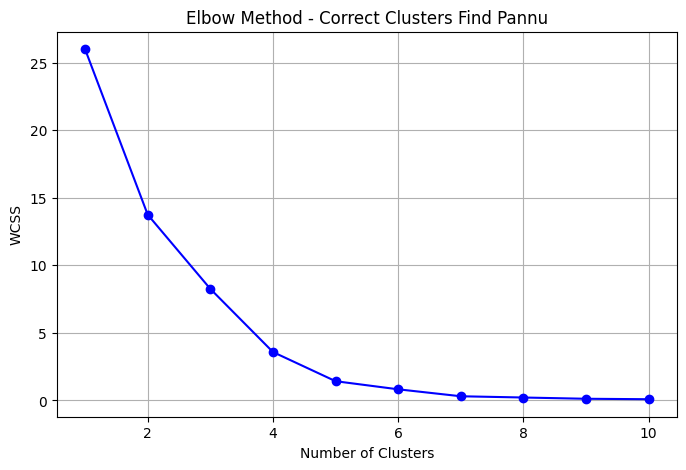

In [4]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# ─────────────────────────
# Elbow Method
# 1 to 10 clusters try pannu
# WCSS = Within Cluster Sum of Squares
# ─────────────────────────
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(data)
    wcss.append(kmeans.inertia_)  # inertia = WCSS

# Graph
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker="o", color="blue")
plt.title("Elbow Method - Correct Clusters Find Pannu")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.grid(True)
plt.show()

In [5]:
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(data)

KMeans(n_clusters=4, random_state=42)

In [8]:
new_student = np.array([[90, 95]])  # New student marks
group = kmeans.predict(new_student)
#print(f"\nNew student marks: Math=20, Science=100")
print(f"Belongs to Group: {group[0]}")

Belongs to Group: 2


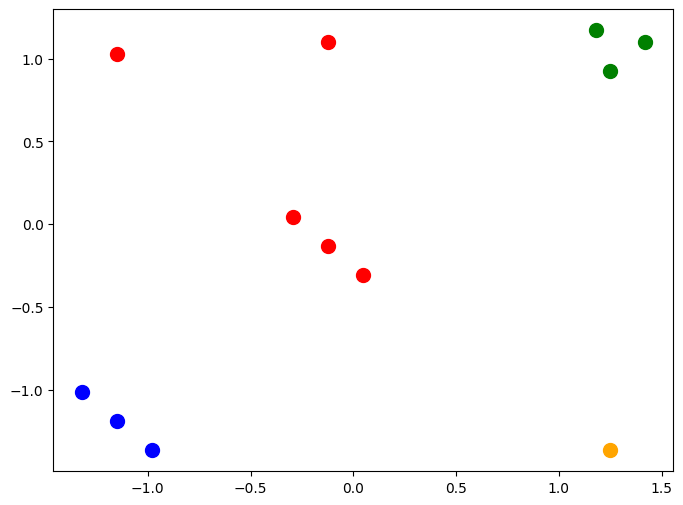

In [ ]:
colors = ["red", "blue", "green", "orange"]
labels = ["Group 0", "Group 1", "Group 2", "Group 3"]

plt.figure(figsize=(8, 6))
# Existing students plot
for i, point in enumerate(data):
    plt.scatter(point[0], point[1],
                color=colors[kmeans.labels_[i]],
                s=100)

In [ ]:
import pandas as pd

df = pd.DataFrame({
    "Student": ["S1","S2","S3","S4","S5","S6","S7","S8","S9","S10","S11","S12"],
    "Name":    ["Rajesh","Priya","Arun","Kavi","Mani","Selvi","Ramu","Gopi","Bala","Kumar","Vikram","Deepa"],
    "Math":    [90, 88, 95, 50, 45, 55, 20, 15, 25, 20, 90, 50],
    "Science": [85, 92, 90, 55, 60, 50, 25, 30, 20, 88, 20, 90],
    "Type":    ["Smart","Smart","Smart",
                "Average","Average","Average",
                "Weak","Weak","Weak",
                "Mixed","Mixed","Mixed"]
})

print(df)

   Student    Name  Math  Science     Type
0       S1  Rajesh    90       85    Smart
1       S2   Priya    88       92    Smart
2       S3    Arun    95       90    Smart
3       S4    Kavi    50       55  Average
4       S5    Mani    45       60  Average
5       S6   Selvi    55       50  Average
6       S7    Ramu    20       25     Weak
7       S8    Gopi    15       30     Weak
8       S9    Bala    25       20     Weak
9      S10   Kumar    20       88    Mixed
10     S11  Vikram    90       20    Mixed
11     S12   Deepa    50       90    Mixed


Group A 🏆 → Rajesh, Priya, Arun     (Both high)

Group B 📚 → Kavi, Mani, Selvi       (Both medium)

Group C 😴 → Ramu, Gopi, Bala        (Both low)

Group D 🤔 → Kumar, Vikram, Deepa    (Mixed - special!)

In [9]:
from sklearn.cluster import DBSCAN
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

# Data
data = np.array([
    [90, 85], [88, 92], [95, 90],
    [50, 55], [45, 60], [55, 50],
    [20, 25], [15, 30], [25, 20],
    [20, 88], [90, 20], [50, 90],
])

# Scale pannu
scaler = MinMaxScaler()
data_scaled = scaler.fit_transform(data)

In [10]:
dbscan = DBSCAN(eps=0.3, min_samples=2)
labels = dbscan.fit_predict(data_scaled)

print("Groups:", labels)

Groups: [ 0  0  0  1  1  1  2  2  2 -1 -1 -1]


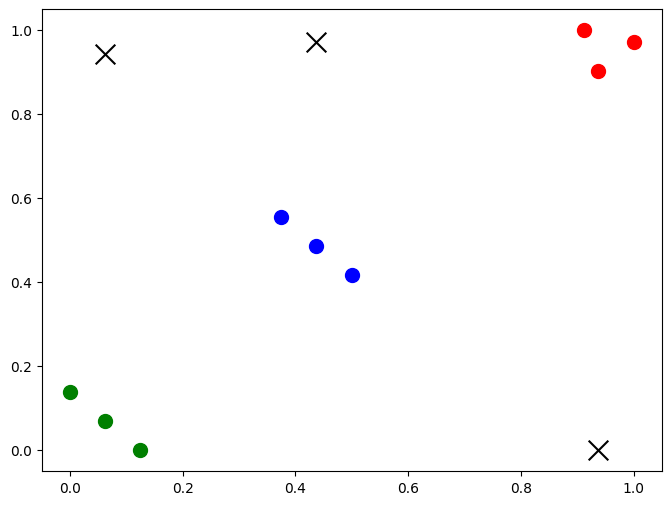

In [11]:
plt.figure(figsize=(8, 6))

unique_labels = set(labels)
colors = ["red", "blue", "green", "purple", "orange"]

for i, point in enumerate(data_scaled):
    if labels[i] == -1:
        # Outlier - black X
        plt.scatter(point[0], point[1],
                    color="black", marker="x", s=200, label="Outlier ❌" if i == list(labels).index(-1) else "")
    else:
        plt.scatter(point[0], point[1],
                    color=colors[labels[i] % len(colors)],
                    s=100)

In [20]:
# New student
new_student = np.array([[90,50]])
new_scaled = scaler.transform(new_student)

# DBSCAN predict - fit_predict use pannanum
all_data = np.vstack([data_scaled, new_scaled])
all_labels = DBSCAN(eps=0.3, min_samples=2).fit_predict(all_data)
new_label = all_labels[-1]
print(new_label)

-1
